In [1]:
import tensorflow as tf

print(tf.__version__)
print(tf.config.list_physical_devices('GPU'))

2.20.0
[PhysicalDevice(name='/physical_device:GPU:0', device_type='GPU')]


In [2]:
from google.colab import files
files.upload()

Saving kaggle.json to kaggle (1).json


[출력 삭제: API 키 포함]

In [3]:
!mkdir -p ~/.kaggle
!cp kaggle.json ~/.kaggle/
!chmod 600 ~/.kaggle/kaggle.json

In [4]:
!kaggle datasets download -d birdy654/cifake-real-and-ai-generated-synthetic-images # cifake
!unzip cifake-real-and-ai-generated-synthetic-images.zip

스트리밍 출력 내용이 길어서 마지막 5000줄이 삭제되었습니다.
  inflating: train/REAL/4500 (10).jpg  
  inflating: train/REAL/4500 (2).jpg  
  inflating: train/REAL/4500 (3).jpg  
  inflating: train/REAL/4500 (4).jpg  
  inflating: train/REAL/4500 (5).jpg  
  inflating: train/REAL/4500 (6).jpg  
  inflating: train/REAL/4500 (7).jpg  
  inflating: train/REAL/4500 (8).jpg  
  inflating: train/REAL/4500 (9).jpg  
  inflating: train/REAL/4500.jpg     
  inflating: train/REAL/4501 (10).jpg  
  inflating: train/REAL/4501 (2).jpg  
  inflating: train/REAL/4501 (3).jpg  
  inflating: train/REAL/4501 (4).jpg  
  inflating: train/REAL/4501 (5).jpg  
  inflating: train/REAL/4501 (6).jpg  
  inflating: train/REAL/4501 (7).jpg  
  inflating: train/REAL/4501 (8).jpg  
  inflating: train/REAL/4501 (9).jpg  
  inflating: train/REAL/4501.jpg     
  inflating: train/REAL/4502 (10).jpg  
  inflating: train/REAL/4502 (2).jpg  
  inflating: train/REAL/4502 (3).jpg  
  inflating: train/REAL/4502 (4).jpg  
  inflating: train/REAL/450

In [5]:
!kaggle datasets download -d birdy654/cifake-real-and-ai-generated-synthetic-images

!kaggle datasets download -d cashbowman/ai-generated-images-vs-real-images

!kaggle datasets download -d alessandrasala79/ai-vs-human-generated-dataset

Dataset URL: https://www.kaggle.com/datasets/birdy654/cifake-real-and-ai-generated-synthetic-images
License(s): other
cifake-real-and-ai-generated-synthetic-images.zip: Skipping, found more recently modified local copy (use --force to force download)
Dataset URL: https://www.kaggle.com/datasets/cashbowman/ai-generated-images-vs-real-images
License(s): Community Data License Agreement - Sharing - Version 1.0
Resuming from 427819008 bytes (71229111 bytes left)...
100% 476M/476M [00:00<00:00, 169MB/s]

Dataset URL: https://www.kaggle.com/datasets/alessandrasala79/ai-vs-human-generated-dataset
License(s): apache-2.0
100% 9.76G/9.76G [02:14<00:00, 78.2MB/s]



In [1]:
!unzip -o -q cifake-real-and-ai-generated-synthetic-images.zip

!unzip -o -q ai-generated-images-vs-real-images.zip

!unzip -o -q ai-vs-human-generated-dataset.zip

In [3]:
!mv /content/train /content/CIFAKE_train
!mv /content/test /content/CIFAKE_test

In [4]:
import os

for root, dirs, files in os.walk('/content'):
    if len(dirs) > 0:
        print(root)
        print(dirs[:5])
        print()

/content
['.config', 'CIFAKE_train', 'data', 'test_data_v2', 'train_data']

/content/.config
['configurations', 'logs']

/content/.config/logs
['2026.05.26']

/content/CIFAKE_train
['REAL', 'FAKE']

/content/data
['real', 'ai']

/content/Ai_generated_dataset
['people', 'city', 'food', 'nature', 'animals']

/content/AiArtData
['AiArtData']

/content/CIFAKE_test
['REAL', 'FAKE']

/content/real_dataset
['people', 'city', 'food', 'nature', 'animals']

/content/RealArt
['RealArt']



In [5]:
from tensorflow.keras.preprocessing.image import ImageDataGenerator

train_datagen = ImageDataGenerator(
    rescale=1./255
)

test_datagen = ImageDataGenerator(
    rescale=1./255
)

In [6]:
train_data = train_datagen.flow_from_directory(
    "/content/CIFAKE_train",
    target_size=(32,32),
    batch_size=32,
    class_mode='binary'
)

Found 100000 images belonging to 2 classes.


In [7]:
test_data = test_datagen.flow_from_directory(
    "/content/CIFAKE_test",
    target_size=(32,32),
    batch_size=32,
    class_mode='binary'
)

Found 20000 images belonging to 2 classes.


In [8]:
from tensorflow.keras.models import Sequential
from tensorflow.keras.layers import Conv2D
from tensorflow.keras.layers import MaxPooling2D
from tensorflow.keras.layers import Flatten
from tensorflow.keras.layers import Dense

model = Sequential()

model.add(Conv2D(32, (3,3),
                 activation='relu',
                 input_shape=(32,32,3)))

model.add(MaxPooling2D(2,2))

model.add(Conv2D(64, (3,3),
                 activation='relu'))

model.add(MaxPooling2D(2,2))

model.add(Flatten())

model.add(Dense(64, activation='relu'))

model.add(Dense(1, activation='sigmoid'))

model.summary()

/usr/local/lib/python3.12/dist-packages/keras/src/layers/convolutional/base_conv.py:113: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ conv2d (Conv2D)                 │ (None, 30, 30, 32)     │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 15, 15, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 13, 13, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 6, 6, 64)       │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 2304)           │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │       147,520 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 166,977 (652.25 KB)

 Trainable params: 166,977 (652.25 KB)

 Non-trainable params: 0 (0.00 B)

In [9]:
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

In [10]:
history = model.fit(
    train_data,
    epochs=10,
    validation_data=test_data
)

Epoch 1/10
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 101s 31ms/step - accuracy: 0.8472 - loss: 0.3413 - val_accuracy: 0.8816 - val_loss: 0.2858
Epoch 2/10
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 46s 15ms/step - accuracy: 0.9127 - loss: 0.2156 - val_accuracy: 0.9184 - val_loss: 0.2089
Epoch 3/10
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 46s 15ms/step - accuracy: 0.9271 - loss: 0.1833 - val_accuracy: 0.9308 - val_loss: 0.1782
Epoch 4/10
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 45s 15ms/step - accuracy: 0.9348 - loss: 0.1633 - val_accuracy: 0.9348 - val_loss: 0.1664
Epoch 5/10
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 47s 15ms/step - accuracy: 0.9416 - loss: 0.1479 - val_accuracy: 0.9347 - val_loss: 0.1672
Epoch 6/10
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 45s 14ms/step - accuracy: 0.9467 - loss: 0.1356 - val_accuracy: 0.9366 - val_loss: 0.1653
Epoch 7/10
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 46s 15ms/step - accuracy: 0.9512 - loss: 0.1225 - val_accuracy: 0.9367 - val_loss: 0.1694
Epoch 8/10
3125/3125 ━━━━━━━━━━━━━━━━━━━━ 45s 15ms/step - accuracy: 0.9568 

In [13]:
print(train_data.samples)
print(test_data.samples)

100000
20000


In [14]:
loss, accuracy = model.evaluate(test_data)

print("Test Loss:", loss)
print("Test Accuracy:", accuracy)

625/625 ━━━━━━━━━━━━━━━━━━━━ 8s 13ms/step - accuracy: 0.9381 - loss: 0.1704
Test Loss: 0.17037710547447205
Test Accuracy: 0.9380999803543091


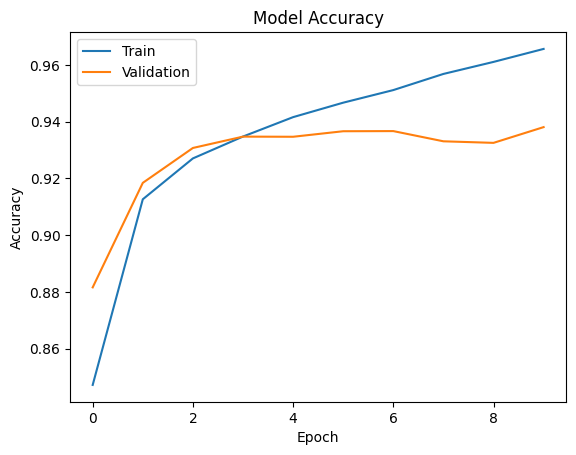

In [15]:
import matplotlib.pyplot as plt

plt.plot(history.history['accuracy'])
plt.plot(history.history['val_accuracy'])

plt.title('Model Accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')

plt.legend(['Train', 'Validation'])

plt.show()

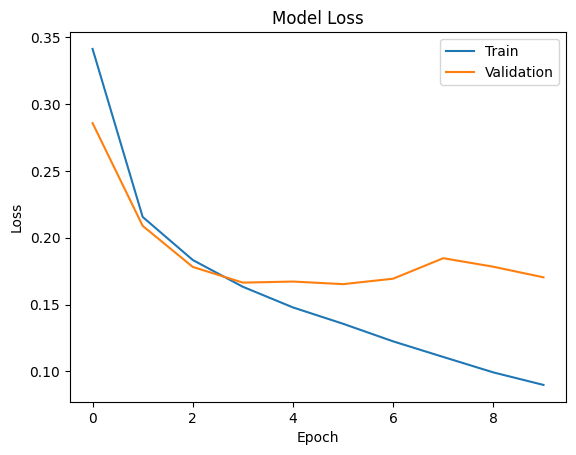

In [16]:
plt.plot(history.history['loss'])
plt.plot(history.history['val_loss'])

plt.title('Model Loss')
plt.xlabel('Epoch')
plt.ylabel('Loss')

plt.legend(['Train', 'Validation'])

plt.show()

1/1 ━━━━━━━━━━━━━━━━━━━━ 1s 518ms/step


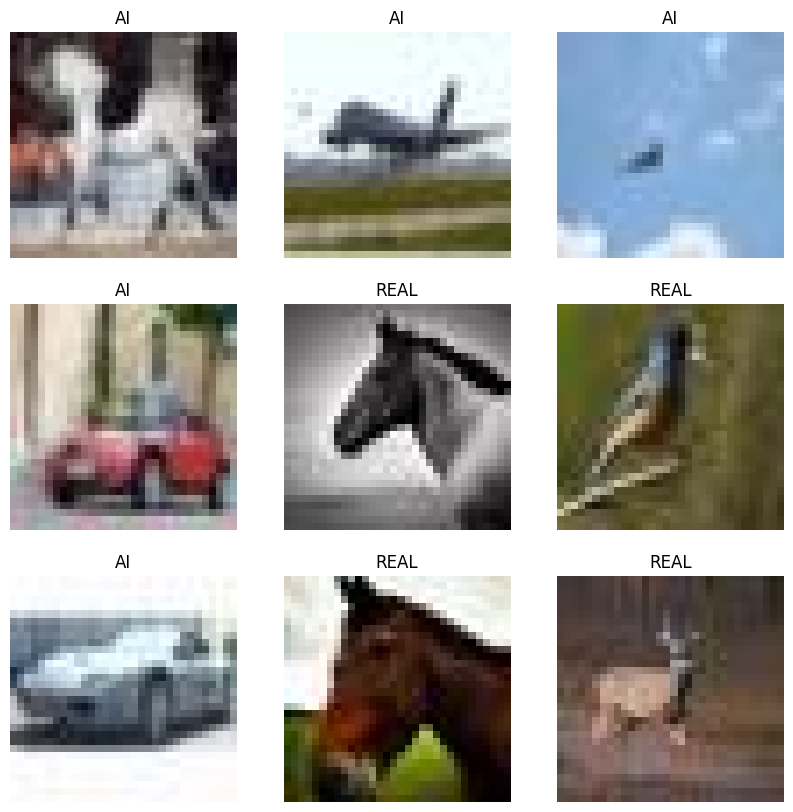

In [17]:
import numpy as np

images, labels = next(test_data)

predictions = model.predict(images)

plt.figure(figsize=(10,10))

for i in range(9):

    plt.subplot(3,3,i+1)

    plt.imshow(images[i])

    pred = predictions[i][0]

    if pred > 0.5:
        text = "AI"
    else:
        text = "REAL"

    plt.title(text)

    plt.axis('off')

plt.show()

In [18]:
print(test_data.class_indices)

{'FAKE': 0, 'REAL': 1}


In [19]:
new_train = train_datagen.flow_from_directory(
    "/content/Dataset",
    target_size=(32,32),
    batch_size=32,
    class_mode='binary'
)

FileNotFoundError: [Errno 2] No such file or directory: '/content/NewDataset'